In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn 

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [146]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
plt.style.use("ggplot")

In [4]:
df=pd.read_csv("email_dataset.csv")

In [5]:
df.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [6]:
df

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...
5571,ham,Rofl. Its true to its name


In [7]:
df.tail(1)

,Category,Message
5572,"{""mode"":""full""",isActive:false}


In [9]:
df["Category"].value_counts()

Category
ham               4825
spam               747
{"mode":"full"       1
Name: count, dtype: int64

In [10]:
df=df.iloc[:-1]

In [11]:
df.tail()

,Category,Message
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...
5571,ham,Rofl. Its true to its name


In [12]:
df.shape

(5572, 2)

In [13]:
df.dtypes

Category    object
Message     object
dtype: object

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5572 non-null   object
 1   Message   5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [15]:
df.isnull()

,Category,Message
0,False,False
1,False,False
2,False,False
3,False,False
4,False,False
...,...,...
5567,False,False
5568,False,False
5569,False,False
5570,False,False


In [16]:
df.isnull().sum()

Category    0
Message     0
dtype: int64

In [17]:
df.isnull().sum().sum()

np.int64(0)

In [18]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
5567    False
5568    False
5569    False
5570    False
5571    False
Length: 5572, dtype: bool

In [19]:
df.duplicated().sum()

np.int64(415)

In [20]:
df.duplicated().sum() /df.shape[0]

np.float64(0.07447954055994258)

In [21]:
df.drop_duplicates(inplace=True)

C:\Users\ACH\AppData\Local\Temp\ipykernel_308\3006716147.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop_duplicates(inplace=True)


In [22]:
df

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [23]:
df["Category"].value_counts()

Category
ham     4516
spam     641
Name: count, dtype: int64

In [25]:
df["Category"].value_counts(normalize=True)*100

Category
ham     87.570293
spam    12.429707
Name: proportion, dtype: float64

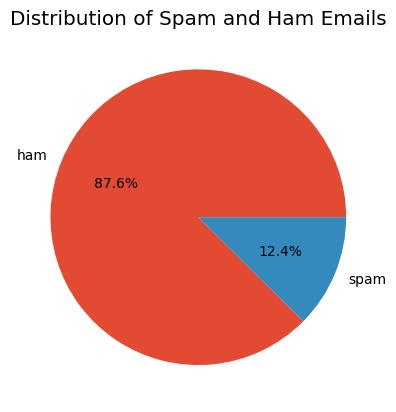

In [31]:
df["Category"].value_counts().plot(
     kind="pie",
     autopct="%1.1f%%"

)
plt.ylabel("")
plt.title("Distribution of Spam and Ham Emails")
plt.show()

In [32]:
df

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [49]:
df.head()

,Category,Message,Message_length,Message_longeur,Message_longeure
0,ham,"Go until jurong point, crazy.. Available only ...",111,111,111
1,ham,Ok lar... Joking wif u oni...,29,29,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,155,155
3,ham,U dun say so early hor... U c already then say...,49,49,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,61,61


In [50]:
df = df.drop(columns=["Message_length"])
df = df.drop(columns=["Message_longeur"])
df = df.drop(columns=["Message_longeure"])

In [53]:
df["Messge_length"]=df["Message"].apply(len)

In [54]:
df.head()

,Category,Message,Messge_length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


In [55]:
df["Messge_length"].describe()

count    5157.000000
mean       79.103936
std        58.382922
min         2.000000
25%        36.000000
50%        61.000000
75%       118.000000
max       910.000000
Name: Messge_length, dtype: float64

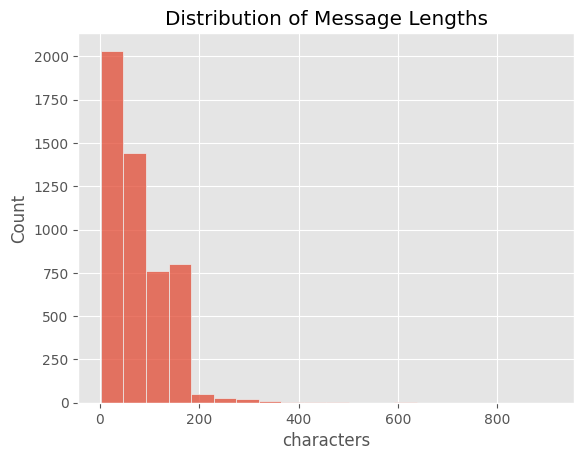

In [62]:
sns.histplot(df["Messge_length"],bins=20)
plt.title("Distribution of Message Lengths")
plt.xlabel("characters")
plt.show()

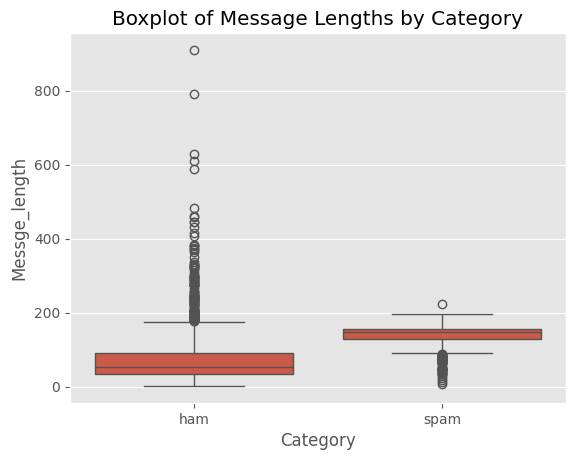

In [64]:
sns.boxplot(
    data=df,
    x="Category",
    y="Messge_length"
)
plt.title("Boxplot of Message Lengths by Category")
plt.show()

In [66]:
df.groupby("Category")["Messge_length"].mean()

Category
ham      70.869353
spam    137.118565
Name: Messge_length, dtype: float64

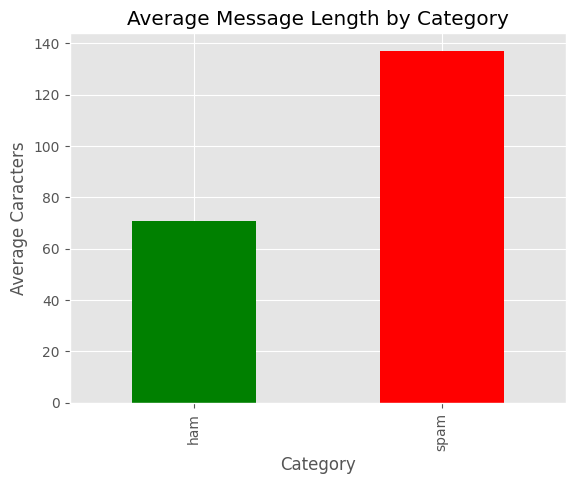

In [67]:
df.groupby("Category")["Messge_length"].mean().plot(
    kind="bar",
    color=["green","red"]
)
plt.ylabel("Average Caracters")
plt.title("Average Message Length by Category")
plt.show()

In [68]:
df["word_count"]=df["Message"].apply(lambda x : len(x.split()))

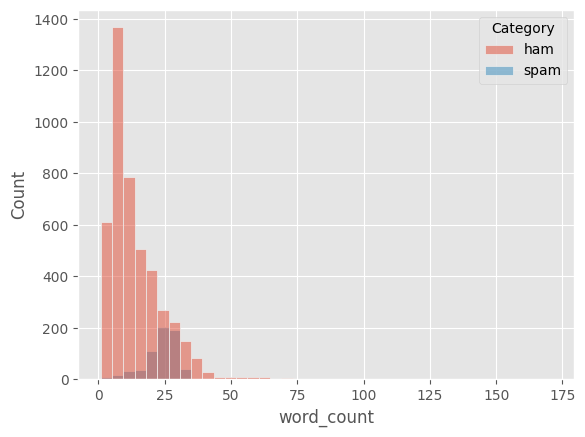

In [72]:
sns.histplot(
    data= df,
    x= "word_count",
    hue= "Category",
    bins= 40
)
plt.show()

In [73]:
df.groupby("Category")["word_count"].mean()

Category
ham     14.239814
spam    23.659906
Name: word_count, dtype: float64

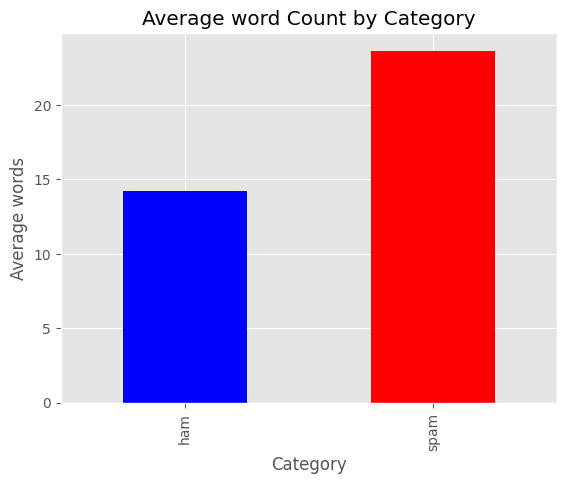

In [74]:
df.groupby("Category")["word_count"].mean().plot(
    kind="bar",
    color=["blue","red"],
    
)
plt.ylabel("Average words")
plt.title("Average word Count by Category")
plt.show()

In [78]:
df.nsmallest(10,"Messge_length")

,Category,Message,Messge_length,word_count
1925,ham,Ok,2,1
3376,ham,:),2,1
261,ham,Yup,3,1
1612,ham,645,3,1
2182,ham,Ok.,3,1
287,ham,Ok..,4,1
2602,ham,Okie,4,1
5173,ham,U 2.,4,2
1273,ham,Ok...,5,1
4293,ham,G.W.R,5,1


In [79]:
df.nlargest(10,"Messge_length")

,Category,Message,Messge_length,word_count
1085,ham,For me the love should start with attraction.i...,910,171
1863,ham,The last thing i ever wanted to do was hurt yo...,790,162
2434,ham,Indians r poor but India is not a poor country...,629,109
1579,ham,How to Make a girl Happy? It's not at all diff...,611,103
2158,ham,Sad story of a Man - Last week was my b'day. M...,588,125
2380,ham,"Good evening Sir, hope you are having a nice d...",482,98
3017,ham,"&lt;#&gt; is fast approaching. So, Wish u a v...",461,66
1513,ham,"Hey sweet, I was wondering when you had a mome...",458,95
2370,ham,A Boy loved a gal. He propsd bt she didnt mind...,446,96
2408,ham,Solve d Case : A Man Was Found Murdered On &l...,444,71


In [82]:
pd.set_option("display.max_colwidth", None)

In [ ]:
df[df["Category"]=="spam"].sample(5)

ValueError: a must be greater than 0 unless no samples are taken

In [88]:
df[df["Category"]=="ham"].sample(5,random_state=1)

,Category,Message,Messge_length,word_count
1258,ham,Am also doing in cbe only. But have to pay.,43,10
5180,ham,"Babe! I fucking love you too !! You know? Fuck it was so good to hear your voice. I so need that. I crave it. I can't get enough. I adore you, Ahmad *kisses*",157,34
1296,ham,TELL HER I SAID EAT SHIT.,25,6
4886,ham,Poor girl can't go one day lmao,31,7
266,ham,Same. Wana plan a trip sometme then,35,7


In [89]:
df["Category"]=df["Category"].map({
    "ham":0,
    "spam":1
})

In [91]:
df.head()

,Category,Message,Messge_length,word_count
0,0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",111,20
1,0,Ok lar... Joking wif u oni...,29,6
2,1,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,155,28
3,0,U dun say so early hor... U c already then say...,49,11
4,0,"Nah I don't think he goes to usf, he lives around here though",61,13


In [92]:
import warnings
warnings.filterwarnings("ignore")

In [93]:
from sklearn.model_selection import train_test_split

In [114]:
X=df["Message"]

In [115]:
y=df["Category"]

In [117]:
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y
)

In [118]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1,2)
)

In [119]:
X_train_tfidf = tfidf.fit_transform(X_train)

In [120]:
X_test_tfidf = tfidf.transform(X_test) 

In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,roc_auc_score
from sklearn.model_selection import RandomizedSearchCV


In [ ]:
models = {
      
    "LogisticRegression":(
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000 
        ),
        {
            "C":[0.01,0.1,1,10,100]
        }
    ),
    "LinearSVC":(
        LinearSVC(
            class_weight="balanced",
           
        ),
        {
            "C":[0.01,0.1,1,10,100]
        }
    ),
    
    "KNN":(
        KNeighborsClassifier(),
        {
            "n_neighbors":[3,5,7,9],
        }
    )
    
}

In [ ]:
resultats=[]
best_models={}
for name,(model,para) in models.items():
    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=para,
        n_iter=5,
        cv=5,
        scoring="f1",
        
     )
    search.fit(X_train_tfidf, y_train)
    best_model = search.best_estimator_
    best_models [name]=best_model
    predictions = best_models[name].predict(X_test_tfidf)
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)
    
    resultats.append({
    
    "Model":name,
    "Best Parameters":search.best_params_,
    "Accuracy":accuracy,
    "Precision":precision,
    "Recall":recall,
    "F1 Score":f1,
    
 })

In [136]:
resultats

[{'Model': 'LogisticRegression',
  'Best Parameters': {'C': 10},
  'Accuracy': 0.9806201550387597,
  'Precision': 0.95,
  'Recall': 0.890625,
  'F1 Score': 0.9193548387096774},
 {'Model': 'LinearSVC',
  'Best Parameters': {'C': 1},
  'Accuracy': 0.9806201550387597,
  'Precision': 0.9655172413793104,
  'Recall': 0.875,
  'F1 Score': 0.9180327868852459},
 {'Model': 'KNN',
  'Best Parameters': {'n_neighbors': 3},
  'Accuracy': 0.9205426356589147,
  'Precision': 1.0,
  'Recall': 0.359375,
  'F1 Score': 0.5287356321839081}]

In [137]:
resultats_df = pd.DataFrame(resultats)
resultats_df=resultats_df.sort_values(by="F1 Score",ascending=False)

In [138]:
resultats_df

,Model,Best Parameters,Accuracy,Precision,Recall,F1 Score
0,LogisticRegression,{'C': 10},0.980620,0.950000,0.890625,0.919355
1,LinearSVC,{'C': 1},0.980620,0.965517,0.875000,0.918033
2,KNN,{'n_neighbors': 3},0.920543,1.000000,0.359375,0.528736
